# Task 8 – Yes/No Audio Classification (torchaudio YESNO)
Digital Speech Processing

**Student:** Abbas Almijbilee (عباس المجبلي)  
**Student ID:** 404131082

Steps:
1. Load the dataset and inspect signal, sample rate and labels
2. Visualize waveform, spectrogram and mel-spectrogram
3. Segment each recording into its 8 words (energy-based)
   - 3b: first version of the segmentation, kept for comparison
4. Extract MFCC features and split train/test by recording
5. Train and compare five classifiers
6. Test robustness of the classifiers to additive noise

## Step 1 – Load the dataset

In [ ]:
!pip install -q torchcodec

import os
import numpy as np
import torch, torchaudio
import matplotlib.pyplot as plt
from IPython.display import Audio

os.makedirs("./data", exist_ok=True)
os.makedirs("./figures", exist_ok=True)
ds = torchaudio.datasets.YESNO(root="./data", download=True)
print("Number of recordings:", len(ds))

waveform, sr, labels = ds[0]
print("Waveform shape:", waveform.shape)
print("Sample rate:", sr)
print("Duration (s):", round(waveform.shape[1] / sr, 2))
print("Labels:", labels)

Audio(waveform.numpy(), rate=sr)

100%|██████████| 4.49M/4.49M [00:02<00:00, 1.57MB/s]


Number of recordings: 60
Waveform shape: torch.Size([1, 50800])
Sample rate: 8000
Duration (s): 6.35
Labels: [0, 0, 0, 0, 1, 1, 1, 1]


## Step 2 – Dataset overview and visualization

Total words: 480
Yes (1): 251 | No (0): 229
Duration min / mean / max (s): 4.94 6.13 6.98


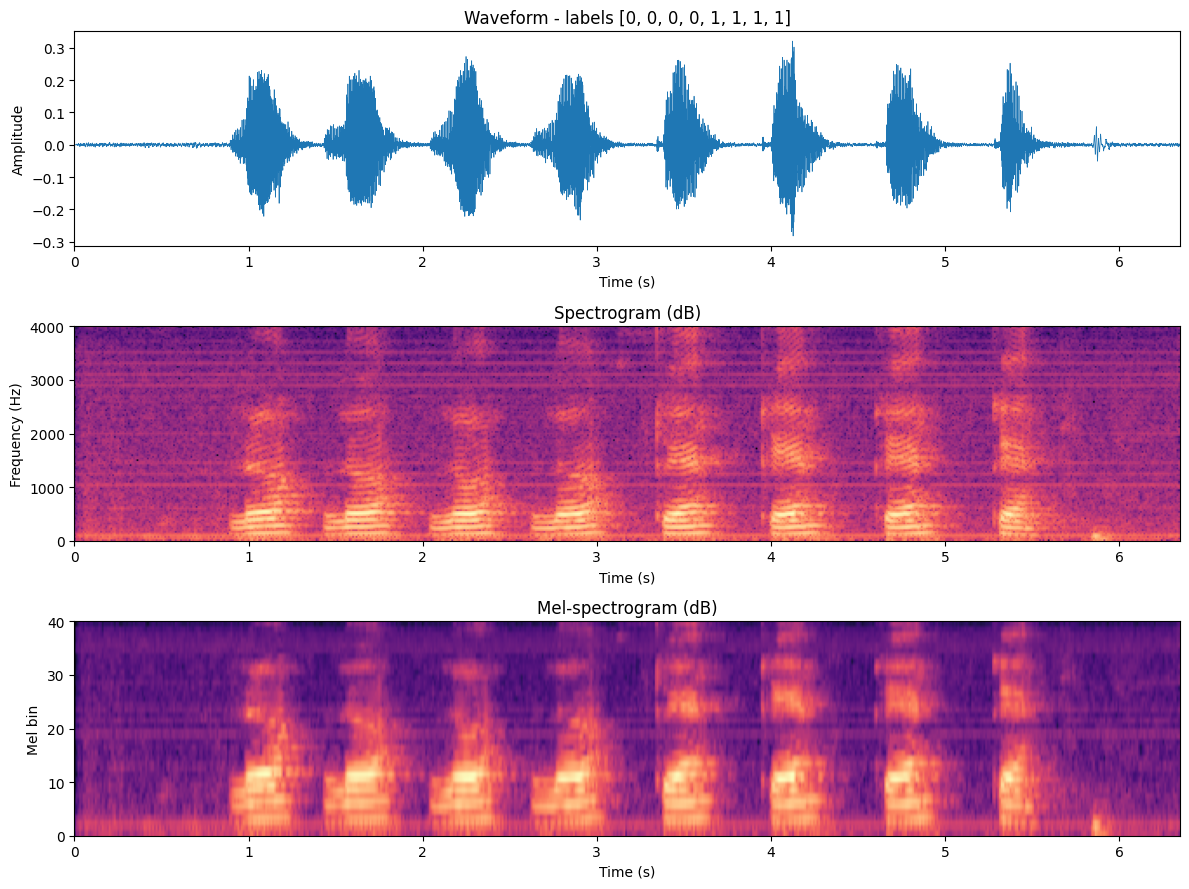

In [ ]:
durations = [w.shape[1] / s for w, s, _ in ds]
all_labels = [l for _, _, lab in ds for l in lab]
print("Total words:", len(all_labels))
print("Yes (1):", sum(all_labels), "| No (0):", len(all_labels) - sum(all_labels))
print("Duration min / mean / max (s):",
      round(min(durations), 2), round(np.mean(durations), 2), round(max(durations), 2))

x = waveform[0].numpy()
t = np.arange(len(x)) / sr

spec = torchaudio.transforms.Spectrogram(n_fft=256, hop_length=80)(waveform)
mel = torchaudio.transforms.MelSpectrogram(sample_rate=sr, n_fft=256,
                                           hop_length=80, n_mels=40)(waveform)
to_db = torchaudio.transforms.AmplitudeToDB()

fig, axes = plt.subplots(3, 1, figsize=(12, 9))
axes[0].plot(t, x, linewidth=0.5)
axes[0].set_title(f"Waveform - labels {labels}")
axes[0].set_xlabel("Time (s)"); axes[0].set_ylabel("Amplitude")
axes[0].set_xlim(0, t[-1])

axes[1].imshow(to_db(spec)[0], origin="lower", aspect="auto",
               extent=[0, t[-1], 0, sr / 2], cmap="magma")
axes[1].set_title("Spectrogram (dB)")
axes[1].set_xlabel("Time (s)"); axes[1].set_ylabel("Frequency (Hz)")

axes[2].imshow(to_db(mel)[0], origin="lower", aspect="auto",
               extent=[0, t[-1], 0, 40], cmap="magma")
axes[2].set_title("Mel-spectrogram (dB)")
axes[2].set_xlabel("Time (s)"); axes[2].set_ylabel("Mel bin")
plt.tight_layout()
plt.savefig("figures/waveform_spectrogram.png", dpi=150)
plt.show()

## Step 3 – Word segmentation (energy-based)

Recordings segmented: 59 / 60
Failed recordings: [21]
Total word segments: 472
Word length min / mean / max (s): 0.26 0.41 0.56


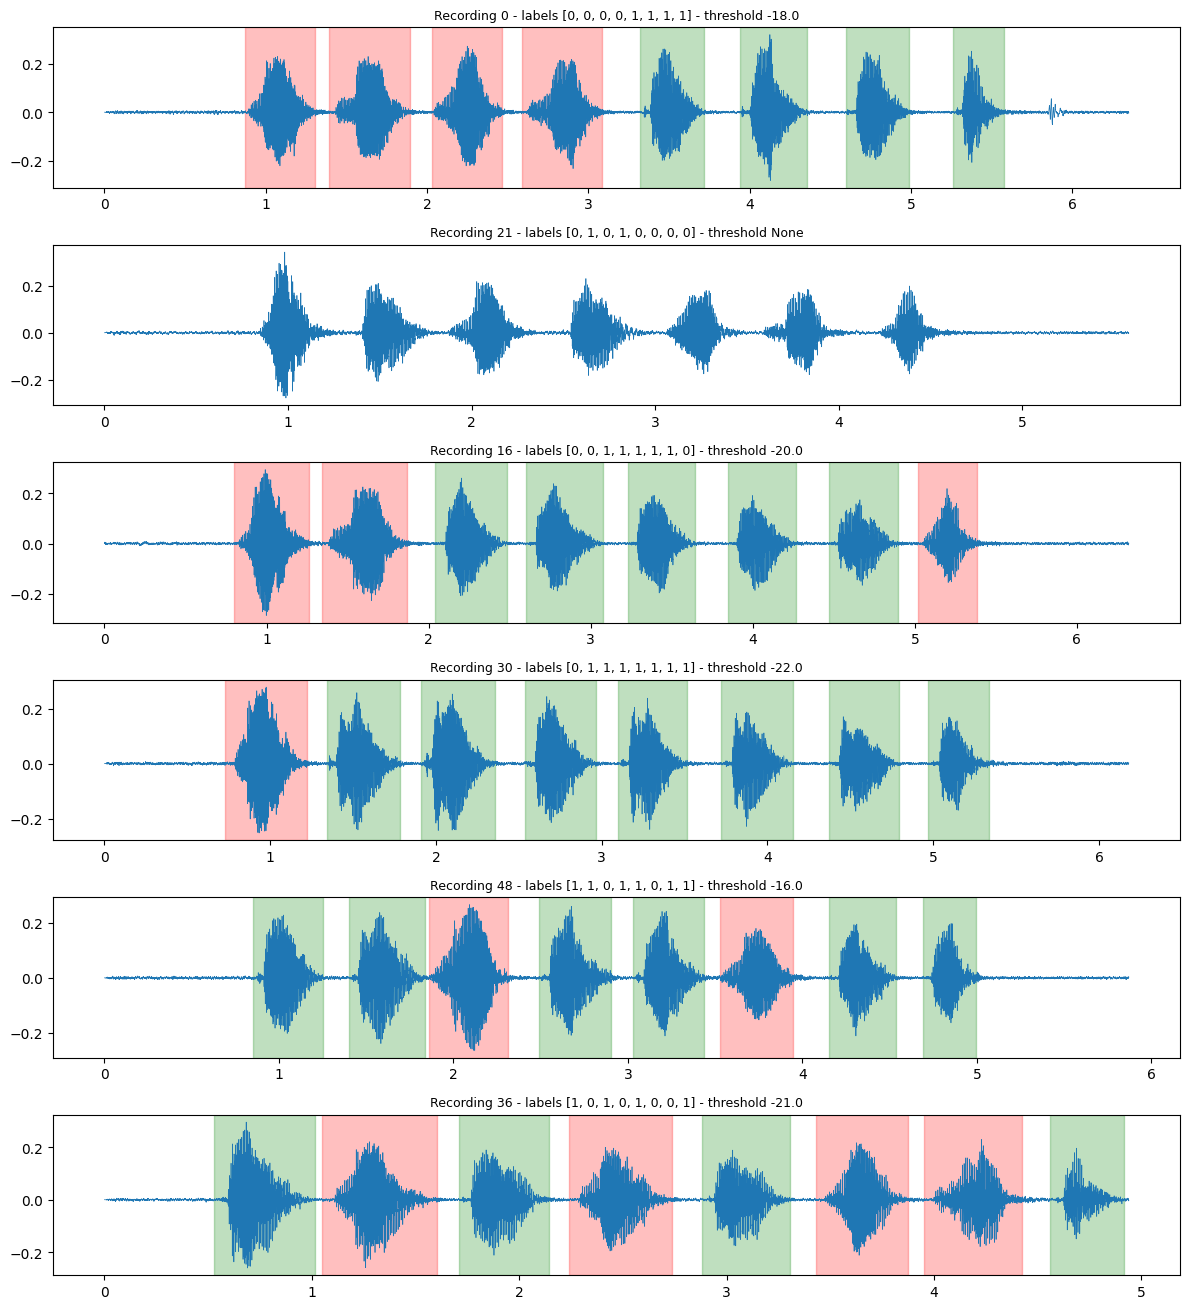

In [ ]:
def frame_energy_db(x, frame=200, hop=80):
    n = 1 + (len(x) - frame) // hop
    idx = np.arange(frame)[None, :] + hop * np.arange(n)[:, None]
    return 10 * np.log10((x[idx] ** 2).mean(axis=1) + 1e-10)

def find_regions(active, min_gap, min_len):
    regions, start = [], None
    for i, a in enumerate(active):
        if a and start is None:
            start = i
        elif not a and start is not None:
            regions.append([start, i]); start = None
    if start is not None:
        regions.append([start, len(active)])
    merged = []
    for r in regions:
        if merged and r[0] - merged[-1][1] < min_gap:
            merged[-1][1] = r[1]
        else:
            merged.append(r)
    return [r for r in merged if r[1] - r[0] >= min_len]

def segment_words(x, sr, n_words=8, frame=200, hop=80, pad=0.05,
                  max_word=1.0, peak_drop=15):
    e = frame_energy_db(x, frame, hop)
    min_gap = int(0.05 * sr / hop)   # 50 ms
    min_len = int(0.10 * sr / hop)   # 100 ms
    valid = []
    for th in np.arange(-40, -4, 1.0):
        regs = find_regions(e > e.max() + th, min_gap, min_len)
        # drop weak regions (clicks / background noise)
        regs = [r for r in regs if e[r[0]:r[1]].max() > e.max() - peak_drop]
        if len(regs) != n_words:
            continue
        # reject thresholds where two words got merged
        if max((en - s) * hop / sr for s, en in regs) > max_word:
            continue
        valid.append((th, regs))
    if not valid:
        return None, None
    th, regs = valid[len(valid) // 2]   # middle of the valid threshold range
    p = int(pad * sr)
    segs = [(max(0, s * hop - p), min(len(x), en * hop + frame + p)) for s, en in regs]
    return segs, th

words, failed = [], []
for i, (w, s, lab) in enumerate(ds):
    x = w[0].numpy()
    segs, th = segment_words(x, s)
    if segs is None:
        failed.append(i); continue
    for (a, b), l in zip(segs, lab):
        words.append((x[a:b], l, i))

print("Recordings segmented:", len(ds) - len(failed), "/", len(ds))
print("Failed recordings:", failed)
print("Total word segments:", len(words))
lens = [len(wd[0]) / sr for wd in words]
print("Word length min / mean / max (s):",
      round(min(lens), 2), round(np.mean(lens), 2), round(max(lens), 2))

check = [0, 21] + list(np.random.default_rng(0).choice(len(ds), 4, replace=False))
fig, axes = plt.subplots(len(check), 1, figsize=(12, 2.2 * len(check)))
for ax, i in zip(axes, check):
    x = ds[i][0][0].numpy(); lab = ds[i][2]
    segs, th = segment_words(x, sr)
    ax.plot(np.arange(len(x)) / sr, x, linewidth=0.5)
    if segs:
        for (a, b), l in zip(segs, lab):
            ax.axvspan(a / sr, b / sr, color="green" if l == 1 else "red", alpha=0.25)
    ax.set_title(f"Recording {i} - labels {lab} - threshold {th}", fontsize=9)
plt.tight_layout()
plt.savefig("figures/segmentation_check.png", dpi=150)
plt.show()

### Step 3b – First version of the segmentation (for comparison)
This is the version I tried first. It passes the count check but shifts the labels in some recordings (see the README).

v1 - recordings with 8 regions: 59 / 60
v1 - longest segment (s): 1.7


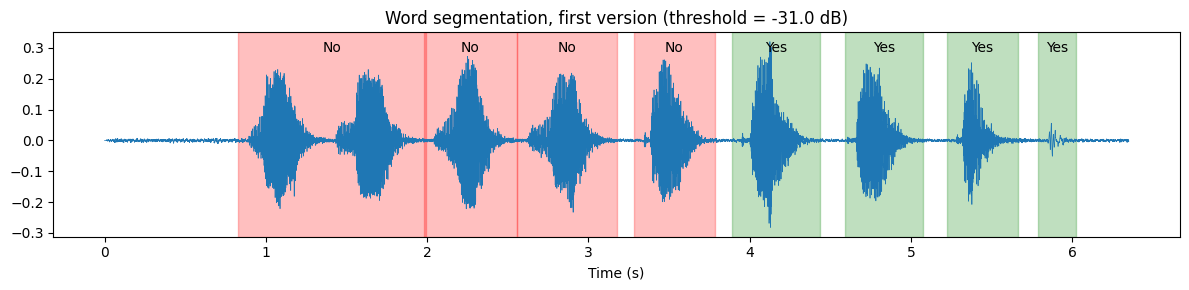

In [ ]:
# First version of the segmentation (kept for comparison).
# It takes the FIRST threshold that gives 8 regions, with a 100 ms merge gap
# and no filtering of weak regions. This version shifted the labels.
def segment_words_v1(x, sr, n_words=8, frame=200, hop=80, pad=0.05):
    e = frame_energy_db(x, frame, hop)
    min_gap = int(0.10 * sr / hop)   # 100 ms
    min_len = int(0.10 * sr / hop)   # 100 ms
    for th in np.arange(-40, -4, 1.0):
        regs = find_regions(e > e.max() + th, min_gap, min_len)
        if len(regs) == n_words:
            p = int(pad * sr)
            return [(max(0, s * hop - p), min(len(x), en * hop + frame + p))
                    for s, en in regs], th
    return None, None

lens_v1, failed_v1 = [], []
for i, (w, s, lab) in enumerate(ds):
    segs, th = segment_words_v1(w[0].numpy(), s)
    if segs is None:
        failed_v1.append(i); continue
    lens_v1 += [(b - a) / s for a, b in segs]
print("v1 - recordings with 8 regions:", len(ds) - len(failed_v1), "/", len(ds))
print("v1 - longest segment (s):", round(max(lens_v1), 2))

x = ds[0][0][0].numpy()
segs, th = segment_words_v1(x, sr)
plt.figure(figsize=(12, 3))
plt.plot(np.arange(len(x)) / sr, x, linewidth=0.5)
for (a, b), l in zip(segs, ds[0][2]):
    plt.axvspan(a / sr, b / sr, color="green" if l == 1 else "red", alpha=0.25)
    plt.text((a + b) / 2 / sr, x.max() * 0.9, "Yes" if l == 1 else "No", ha="center")
plt.title(f"Word segmentation, first version (threshold = {th} dB)")
plt.xlabel("Time (s)")
plt.tight_layout()
plt.savefig("figures/segmentation_first_attempt.png", dpi=150)
plt.show()

## Step 4 – MFCC features and train/test split by recording

In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

mfcc_tf = torchaudio.transforms.MFCC(
    sample_rate=sr, n_mfcc=13,
    melkwargs={"n_fft": 256, "hop_length": 80, "n_mels": 40})

def extract_features(audio):
    m = mfcc_tf(torch.tensor(audio, dtype=torch.float32))
    d = torchaudio.functional.compute_deltas(m)
    return torch.cat([m.mean(1), m.std(1),
                      d.mean(1), d.std(1)]).numpy()

X = np.stack([extract_features(a) for a, _, _ in words])
y = np.array([l for _, l, _ in words])
groups = np.array([g for _, _, g in words])
print("Feature matrix:", X.shape)

gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

train_recs = set(groups[train_idx])
test_recs = set(groups[test_idx])
print("Train:", len(y_train), "words from", len(train_recs), "recordings")
print("Test :", len(y_test), "words from", len(test_recs), "recordings")
print("Shared recordings:", train_recs & test_recs)
print("Train Yes/No:", y_train.sum(), "/", len(y_train) - y_train.sum())
print("Test  Yes/No:", y_test.sum(), "/", len(y_test) - y_test.sum())

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

Feature matrix: (472, 52)
Train: 328 words from 41 recordings
Test : 144 words from 18 recordings
Shared recordings: set()
Train Yes/No: 177 / 151
Test  Yes/No: 72 / 72


## Step 5 – Train and compare classifiers

                      Test accuracy  Test F1  Errors  CV accuracy (mean)  CV accuracy (std)  Train time (s)
Model                                                                                                      
SVM (RBF)                    0.9931   0.9931       1              1.0000             0.0000          0.0095
Neural Network (MLP)         1.0000   1.0000       0              0.9979             0.0042          0.1481
Random Forest                1.0000   1.0000       0              1.0000             0.0000          0.4414
k-NN (k=5)                   1.0000   1.0000       0              0.9979             0.0042          0.0007
Logistic Regression          1.0000   1.0000       0              1.0000             0.0000          0.0153


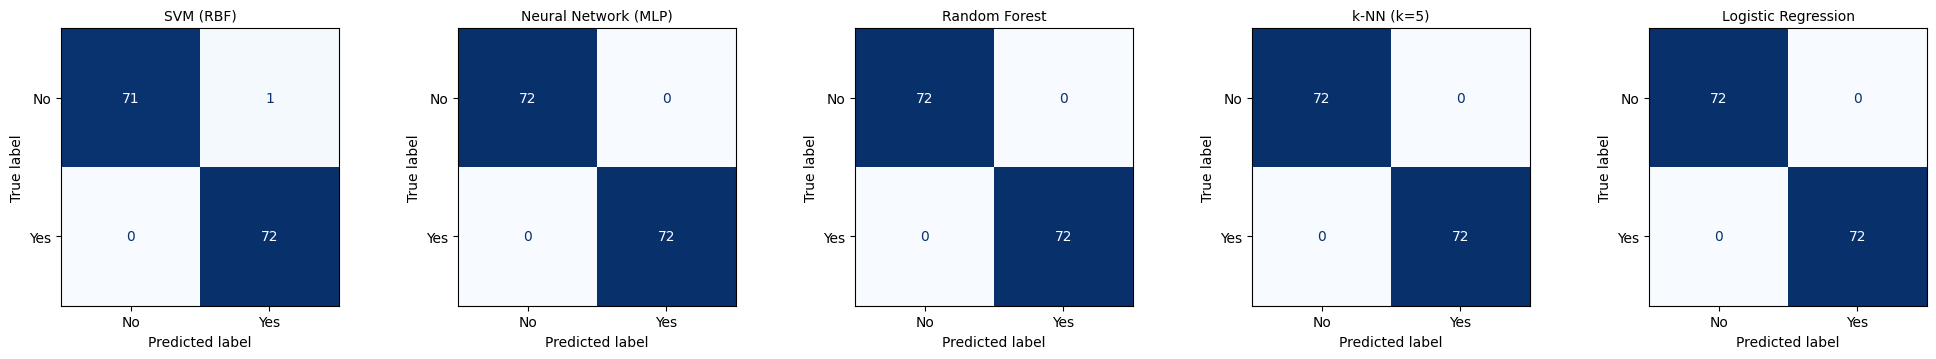

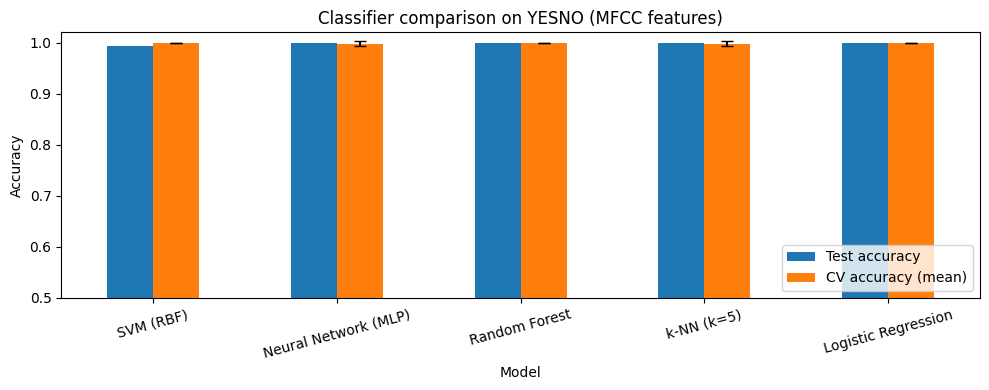

In [ ]:
import time
import pandas as pd
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.metrics import (accuracy_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

models = {
    "SVM (RBF)": SVC(kernel="rbf", C=1.0, gamma="scale"),
    "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(64, 32),
                                          max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "k-NN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Logistic Regression": LogisticRegression(max_iter=1000),
}

results, preds = [], {}
cv = GroupKFold(n_splits=5)

for name, model in models.items():
    t0 = time.time()
    model.fit(X_train_s, y_train)
    train_time = time.time() - t0
    y_pred = model.predict(X_test_s)
    preds[name] = y_pred

    pipe = make_pipeline(StandardScaler(), model)
    cv_scores = cross_val_score(pipe, X, y, groups=groups, cv=cv,
                                scoring="accuracy")

    results.append({
        "Model": name,
        "Test accuracy": accuracy_score(y_test, y_pred),
        "Test F1": f1_score(y_test, y_pred),
        "Errors": int((y_pred != y_test).sum()),
        "CV accuracy (mean)": cv_scores.mean(),
        "CV accuracy (std)": cv_scores.std(),
        "Train time (s)": train_time,
    })

df = pd.DataFrame(results).set_index("Model").round(4)
print(df.to_string())

fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 3.6))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["No", "Yes"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.savefig("figures/confusion_matrices.png", dpi=150)
plt.show()

ax = df[["Test accuracy", "CV accuracy (mean)"]].plot(
    kind="bar", figsize=(10, 4), rot=15,
    yerr={"CV accuracy (mean)": df["CV accuracy (std)"]}, capsize=4)
ax.set_ylim(0.5, 1.02)
ax.set_ylabel("Accuracy")
ax.set_title("Classifier comparison on YESNO (MFCC features)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/accuracy_comparison.png", dpi=150)
plt.show()

## Step 6 – Robustness to additive white noise
Models trained on clean data are tested on noisy versions of the test words (SNR from 20 dB down to 0 dB).

Test accuracy vs. SNR (models trained on clean data):
                       Clean   20 dB   15 dB   10 dB    5 dB    0 dB
SVM (RBF)             0.9931  0.9051  0.7431  0.5463  0.5000  0.5000
Neural Network (MLP)  1.0000  0.7963  0.5741  0.5116  0.5000  0.5000
Random Forest         1.0000  0.9977  0.9861  0.8889  0.7060  0.5324
k-NN (k=5)            1.0000  0.9259  0.9167  0.8495  0.7199  0.5926
Logistic Regression   1.0000  0.8403  0.6019  0.5093  0.5000  0.5000
SVM (RBF): 100% of test words predicted as Yes at 0 dB
Neural Network (MLP): 100% of test words predicted as Yes at 0 dB
Random Forest: 3% of test words predicted as Yes at 0 dB
k-NN (k=5): 88% of test words predicted as Yes at 0 dB
Logistic Regression: 100% of test words predicted as Yes at 0 dB


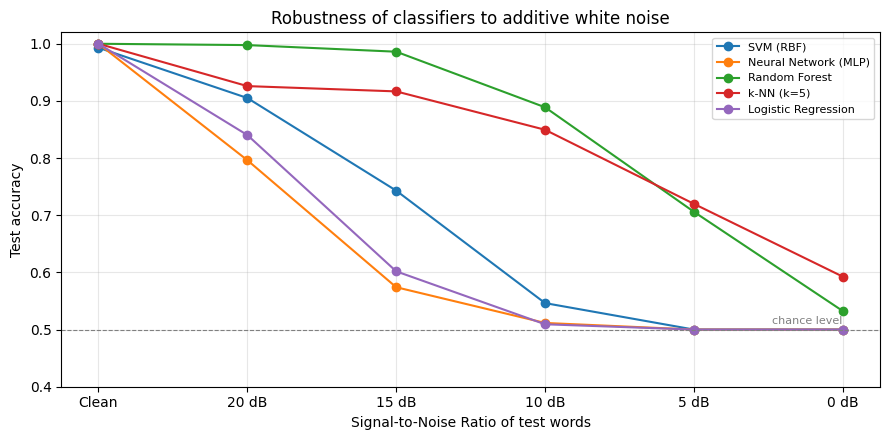

In [ ]:
# ---- Step 6: robustness to additive noise ----
def add_noise(audio, snr_db, rng):
    p_signal = np.mean(audio ** 2)
    p_noise = p_signal / (10 ** (snr_db / 10))
    return audio + rng.normal(0, np.sqrt(p_noise), size=audio.shape)

snr_levels = [None, 20, 15, 10, 5, 0]      # None = clean
n_repeats = 3                              # average over 3 noise draws
test_audio = [words[i][0] for i in test_idx]

noise_results = {name: [] for name in models}
for snr in snr_levels:
    accs = {name: [] for name in models}
    for rep in range(n_repeats if snr is not None else 1):
        rng = np.random.default_rng(rep)
        if snr is None:
            X_noisy = X_test
        else:
            X_noisy = np.stack([extract_features(add_noise(a, snr, rng).astype(np.float32))
                                for a in test_audio])
        X_noisy_s = scaler.transform(X_noisy)
        for name, model in models.items():      # models trained on clean data
            accs[name].append(accuracy_score(y_test, model.predict(X_noisy_s)))
    for name in models:
        noise_results[name].append(np.mean(accs[name]))

labels_snr = ["Clean" if s is None else f"{s} dB" for s in snr_levels]
noise_df = pd.DataFrame(noise_results, index=labels_snr).T.round(4)
print("Test accuracy vs. SNR (models trained on clean data):")
print(noise_df.to_string())

# which class does each model predict under heavy noise (0 dB)?
rng = np.random.default_rng(0)
X0 = scaler.transform(np.stack([
    extract_features(add_noise(a, 0, rng).astype(np.float32)) for a in test_audio]))
for name, model in models.items():
    print(f"{name}: {model.predict(X0).mean():.0%} of test words predicted as Yes at 0 dB")

plt.figure(figsize=(9, 4.5))
for name in models:
    plt.plot(labels_snr, noise_results[name], marker="o", label=name)
plt.axhline(0.5, color="gray", linestyle="--", linewidth=0.8)
plt.text(len(snr_levels) - 1, 0.51, "chance level", ha="right", fontsize=8, color="gray")
plt.ylim(0.4, 1.02)
plt.xlabel("Signal-to-Noise Ratio of test words")
plt.ylabel("Test accuracy")
plt.title("Robustness of classifiers to additive white noise")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/noise_robustness.png", dpi=150)
plt.show()
